In [1]:
from pathlib import Path
import pandas as pd

# 1. Định nghĩa đường dẫn thư mục
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "house-price"

# 2. Đọc tập dữ liệu từ file CSV
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

# 3. Kiểm tra số dòng và số cột
print("Kích thước tập Train:", train.shape)
print("Kích thước tập Test:", test.shape)

Kích thước tập Train: (1460, 81)
Kích thước tập Test: (1459, 80)


In [2]:
from sklearn.model_selection import train_test_split

# 1. Tách đặc trưng X và nhãn y từ bảng train ban đầu
X = train.drop(columns=["SalePrice", "Id"])
y = train["SalePrice"]

# 2. Chia dữ liệu thành tập Train (80%) và Validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Kiểm tra kích thước sau khi chia
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (1168, 79)
X_val shape: (292, 79)
y_train shape: (1168,)
y_val shape: (292,)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns

numeric_pipeline = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")), # Điền chữ 'None' vào chỗ trống
    ("encoder", OneHotEncoder(handle_unknown="ignore"))                 # Chuyển chữ thành số (One-Hot)
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Kích thước X_train sau xử lý:", X_train_processed.shape)
print("Kích thước X_val sau xử lý:", X_val_processed.shape)

Kích thước X_train sau xử lý: (1168, 301)
Kích thước X_val sau xử lý: (292, 301)


In [6]:
import numpy as np
import torch

# 1. Chuyển ma trận thưa (Sparse) thành mảng Dày (Dense) nếu cần
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_val_processed = X_val_processed.toarray()

# 2. Chuyển đặc trưng X thành Tensor kiểu float32
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)

# 3. Biến đổi Log(1 + y) cho giá nhà
y_train_log = np.log1p(y_train.to_numpy())
y_val_log = np.log1p(y_val.to_numpy())

# 4. Chuyển nhãn y thành Tensor và bẻ thành cột
y_train_tensor = torch.tensor(y_train_log, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val_log, dtype=torch.float32).reshape(-1, 1)

print("Kích thước X_train_tensor:", X_train_tensor.shape)
print("Kích thước y_train_tensor:", y_train_tensor.shape)
print("Mẫu giá nhà sau khi lấy Log (thường từ 11 - 13):", y_train_tensor[0].item())

Kích thước X_train_tensor: torch.Size([1168, 301])
Kích thước y_train_tensor: torch.Size([1168, 1])
Mẫu giá nhà sau khi lấy Log (thường từ 11 - 13): 11.884495735168457


In [8]:
import torch
from torch import nn

class HousePriceNet(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

# Lấy số lượng đặc trưng đầu vào từ X_train
num_features = X_train_tensor.shape[1]

# Khởi tạo mô hình và lưu vào biến 'model'
model = HousePriceNet(input_size=num_features)
print(model)

HousePriceNet(
  (network): Sequential(
    (0): Linear(in_features=301, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [ ]:
# 1. Khai báo hàm đo lường mức độ sai lệch (Loss Function)
criterion = nn.MSELoss()

# 2. Khai báo thuật toán tối ưu để cập nhật trọng số (Optimizer)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# 3. torch.optim.Adam là hàm chỉnh sửa trọng số khi thấy loss
print("Hàm tính sai số:", criterion)
print("Thuật toán học:", type(optimizer).__name__)

Hàm tính sai số: MSELoss()
Thuật toán học: Adam


Epoch [50/500] | Train Loss: 0.5388 | Val Loss: 0.8325
Epoch [100/500] | Train Loss: 0.0305 | Val Loss: 0.0420
Epoch [150/500] | Train Loss: 0.0168 | Val Loss: 0.0245
Epoch [200/500] | Train Loss: 0.0135 | Val Loss: 0.0220
Epoch [250/500] | Train Loss: 0.0117 | Val Loss: 0.0205
Epoch [300/500] | Train Loss: 0.0105 | Val Loss: 0.0195
Epoch [350/500] | Train Loss: 0.0097 | Val Loss: 0.0190
Epoch [400/500] | Train Loss: 0.0091 | Val Loss: 0.0186
Epoch [450/500] | Train Loss: 0.0086 | Val Loss: 0.0184
Epoch [500/500] | Train Loss: 0.0083 | Val Loss: 0.0183


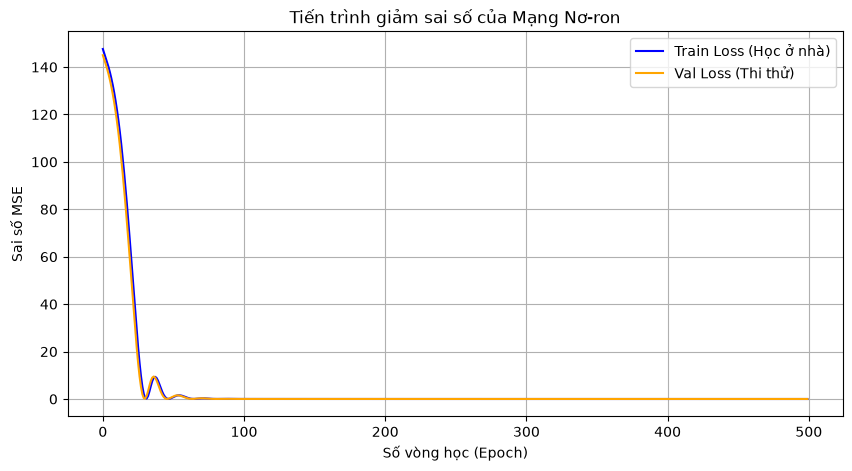

In [10]:
import matplotlib.pyplot as plt

num_epochs = 500
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # ==========================
    # PHẦN 1: HUẤN LUYỆN (TRAIN)
    # ==========================
    model.train() # Chuyển mô hình sang chế độ học
    
    # Bước 1: Lan truyền tiến (Forward Pass) - Dự đoán giá nhà
    y_pred_train = model(X_train_tensor)
    
    # Bước 2: Tính sai số (Loss)
    loss_train = criterion(y_pred_train, y_train_tensor)
    
    # Bước 3: Xóa sạch nháp đạo hàm của vòng lặp trước
    optimizer.zero_grad()
    
    # Bước 4: Lan truyền ngược (Backward Pass) - Tìm nguyên nhân gây lỗi
    loss_train.backward()
    
    # Bước 5: Cập nhật trọng số - Adam tiến hành sửa sai
    optimizer.step()

    # ==========================
    # PHẦN 2: ĐÁNH GIÁ (VALIDATION)
    # ==========================
    model.eval() # Chuyển mô hình sang chế độ làm bài thi
    with torch.no_grad(): # Tắt tính toán đạo hàm để tiết kiệm RAM và thời gian
        y_pred_val = model(X_val_tensor)
        loss_val = criterion(y_pred_val, y_val_tensor)

    # Lưu lại lịch sử Loss để vẽ biểu đồ
    train_losses.append(loss_train.item())
    val_losses.append(loss_val.item())

    # Cứ sau 50 vòng thì in kết quả ra màn hình 1 lần
    if (epoch + 1) % 50 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {loss_train.item():.4f} | Val Loss: {loss_val.item():.4f}")

# Vẽ đồ thị tiến trình học
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss (Học ở nhà)", color='blue')
plt.plot(val_losses, label="Val Loss (Thi thử)", color='orange')
plt.xlabel("Số vòng học (Epoch)")
plt.ylabel("Sai số MSE")
plt.title("Tiến trình giảm sai số của Mạng Nơ-ron")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import pandas as pd
import numpy as np

# 1. Tiền xử lý tập Test (Chỉ dùng transform, tuyệt đối không fit)
X_test = test.drop(columns=["Id"])
X_test_processed = preprocessor.transform(X_test)

# Giải nén ma trận thưa (nếu có)
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Chuyển sang Tensor
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

# 2. Bật chế độ thi cử và tiến hành dự đoán
model.eval()
with torch.no_grad():
    # Dự đoán ra giá trị dạng Log (khoảng 11-13)
    test_preds_log = model(X_test_tensor).numpy() 

print("5 giá trị dự đoán Log đầu tiên:\n", test_preds_log[:5].squeeze())

# 3. Quy đổi ngược từ Log về giá tiền USD thực tế
test_preds_usd = np.expm1(test_preds_log)

# Giới hạn giá nhà tối thiểu là 0 USD (đề phòng mô hình dự đoán ra số âm)
test_preds_usd = np.clip(test_preds_usd, a_min=0, a_max=None) 

# 4. Gom mã Id và Giá nhà vào 1 bảng để xuất file
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_preds_usd.squeeze()
})

# Lưu ra file CSV
submission.to_csv(DATA_DIR / "submission.csv", index=False)
print("\n-> Đã xuất file submission.csv thành công!")
submission.head()

5 giá trị dự đoán Log đầu tiên:
 [11.697367 11.649187 12.061718 12.155691 12.225599]

-> Đã xuất file submission.csv thành công!


,Id,SalePrice
0,1461,120253.632812
1,1462,114597.164062
2,1463,173115.140625
3,1464,190172.312500
4,1465,203942.703125
